<a href="https://colab.research.google.com/github/mayank261193/Rebounce-Applied-AI-and-Analytics-Codes/blob/main/MP4_AirQuality.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Breathing in India

# 1. Load and Understand data

In [6]:
# 1. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [10]:
# 2. Load the data and show the first few rows
# Change the file name to match your file (use pd.read_excel for .xlsx)
df = pd.read_csv("mp4_india_city_aqi_2015_2023.csv", low_memory=False)
df.head()

,date,City,No. Stations,Air Quality,Index Value,Prominent Pollutant
0,01-05-2015,Varanasi,NaN,Moderate,157,PM10
1,01-05-2015,Kanpur,NaN,Moderate,175,PM10
2,01-05-2015,Faridabad,NaN,Moderate,173,PM10
3,01-05-2015,Ahmedabad,NaN,Moderate,168,PM2.5
4,01-05-2015,Hyderabad,NaN,Moderate,189,PM2.5


In [8]:
# 3. Shape, column names and data types
print("Shape:", df.shape)
print("Columns:", list(df.columns))
print(df.dtypes)

Shape: (299974, 6)
Columns: ['date', 'City', 'No. Stations', 'Air Quality', 'Index Value', 'Prominent Pollutant']
date                   object
City                   object
No. Stations           object
Air Quality            object
Index Value             int64
Prominent Pollutant    object
dtype: object


In [11]:
# 4. Missing values in every column
print(df.isna().sum())

date                     0
City                     0
No. Stations           140
Air Quality              0
Index Value              0
Prominent Pollutant      1
dtype: int64


In [13]:
# 5. Rows that repeat the same Date and City
# keep=False marks every row in a repeated group, not just the later ones
dup_mask = df.duplicated(subset=["date", "City"], keep=False)
print("Rows sharing a Date + City with another row:", dup_mask.sum())
print("Extra (repeat) rows beyond the first:", df.duplicated(subset=["date", "City"]).sum())
df[dup_mask].sort_values(["City", "date"]).head(10)

Rows sharing a Date + City with another row: 68
Extra (repeat) rows beyond the first: 34


,date,City,No. Stations,Air Quality,Index Value,Prominent Pollutant
179301,01-04-2022,Aurangabad,1,Very Poor,312,PM10
179302,01-04-2022,Aurangabad,1,Moderate,108,PM10
212131,01-11-2022,Aurangabad,1,Moderate,113,PM10
212132,01-11-2022,Aurangabad,1,Moderate,117,PM2.5
183902,02-05-2022,Aurangabad,1,Moderate,102,PM10
183904,02-05-2022,Aurangabad,1,Moderate,128,PM10
212193,02-11-2022,Aurangabad,1,Moderate,107,PM10
212194,02-11-2022,Aurangabad,1,Moderate,144,PM10
179670,03-04-2022,Aurangabad,1,Very Poor,317,PM10
179671,03-04-2022,Aurangabad,1,Moderate,111,PM10


In [17]:
 # 6. Number of cities and the date range
print("Different cities:", df["City"].nunique())
dates = pd.to_datetime(df["date"], errors="coerce")   # works even if Date is text
print("First date:", dates.min())
print("Last date:", dates.max())
print("Dates that could not be read:", dates.isna().sum())

Different cities: 277
First date: 2015-01-05 00:00:00
Last date: 2023-12-12 00:00:00
Dates that could not be read: 182479


In [18]:
 # 7. Count of each value in Air Quality
print(df["Air Quality"].value_counts(dropna=False))
# Inspect exact spellings, including hidden spaces and capital letters
print(sorted(df["Air Quality"].dropna().unique(), key=str))
# "Very poor" is repeated two time with different capitalisation

Air Quality
Satisfactory    105251
Moderate         96139
Good             47440
Poor             34641
Very Poor        13969
Severe            2516
Very poor           18
Name: count, dtype: int64
['Good', 'Moderate', 'Poor', 'Satisfactory', 'Severe', 'Very Poor', 'Very poor']


 what needs cleaning before you can trust this data?                 


  

1.   There are 140 missing station names hence i would drop that column or flag the city and exclude it from comparison.
2.   There is spelling error in Air quality index "Very poor" which lead to error of duplication.



# 2. Clean the Data

In [20]:
df = pd.read_csv("mp4_india_city_aqi_2015_2023.csv", low_memory=False)   # change to your file name
print("Start:", df.shape)

Start: (299974, 6)


In [22]:
# 1. Convert date to datetime with dayfirst=True
df["date"] = pd.to_datetime(df["date"], dayfirst=True)
print("After 1 (datetime):", df.shape)

After 1 (datetime): (299974, 6)


In [23]:
# 2. Fix Air Quality spellings so each category appears once
df["Air Quality"] = df["Air Quality"].str.strip().str.title()
print(df["Air Quality"].value_counts())   # check: each category should appear once
print("After 2 (spellings):", df.shape)

Air Quality
Satisfactory    105251
Moderate         96139
Good             47440
Poor             34641
Very Poor        13987
Severe            2516
Name: count, dtype: int64
After 2 (spellings): (299974, 6)


In [24]:
# 3. Remove repeated city-days, keeping the first one
df = df.drop_duplicates(subset=["City", "date"], keep="first")
print("After 3 (duplicates):", df.shape)

After 3 (duplicates): (299940, 6)


In [28]:
# 4. Drop the No. Stations column safely if it exists
df = df.drop(columns=["No. Stations"], errors="ignore")
print("After 4 (drop column):", df.shape)
# Why it's safe to drop "Stations" Column?
#No. of  Stations only describes how many monitors reported that day
# it do not  tell air quality itself,so it doesn't affect the  analysis.

After 4 (drop column): (299940, 5)


In [29]:
# 5. Create year and month columns
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
print("After 5 (year, month):", df.shape)

After 5 (year, month): (299940, 7)


In [30]:
# 6. Optional: replace OZONE with O3
df["Prominent Pollutant"] = df["Prominent Pollutant"].replace("OZONE", "O3")
print("After 6 (OZONE -> O3):", df.shape)

After 6 (OZONE -> O3): (299940, 7)


# 3. Describe the AQI with statistics

In [33]:
delhi = df[df["City"] == "Delhi"]

In [34]:
# [1,2,3] Mean, median, std, min, max, Q1, Q3, IQR, skew
def describe(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return {"mean": s.mean(), "median": s.median(), "std": s.std(),
            "min": s.min(), "max": s.max(),
            "Q1": q1, "Q3": q3, "IQR": q3 - q1,
            "skew": s.skew()}

summary = pd.DataFrame({
    "India": describe(df["Index Value"]),
    "Delhi": describe(delhi["Index Value"]),
}).round(2)
print(summary)

         India   Delhi
mean    124.69  217.14
median   99.00  209.00
std      85.09  104.01
min       3.00   41.00
max     500.00  497.00
Q1       62.00  127.00
Q3      162.00  296.00
IQR     100.00  169.00
skew      1.34    0.30


In [35]:
# 4. Count Delhi outliers using the IQR rule
s = delhi["Index Value"]
q1, q3 = s.quantile(0.25), s.quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
n_outliers = (s > upper_fence).sum()
print("Upper fence:", upper_fence)
print("Delhi outlier days:", n_outliers)

Upper fence: 549.5
Delhi outlier days: 0


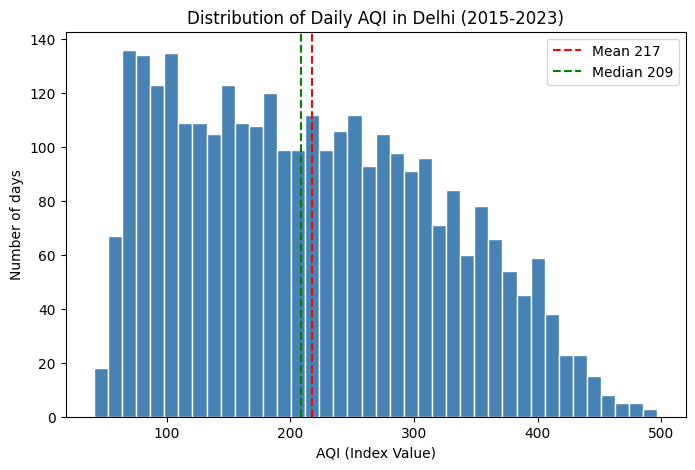

In [36]:
# 5. Histogram of Delhi AQI
plt.figure(figsize=(8, 5))
plt.hist(s, bins=40, color="steelblue", edgecolor="white")
plt.axvline(s.mean(), color="red", ls="--", label=f"Mean {s.mean():.0f}")
plt.axvline(s.median(), color="green", ls="--", label=f"Median {s.median():.0f}")
plt.title("Distribution of Daily AQI in Delhi (2015-2023)")
plt.xlabel("AQI (Index Value)")
plt.ylabel("Number of days")
plt.legend()
plt.show()

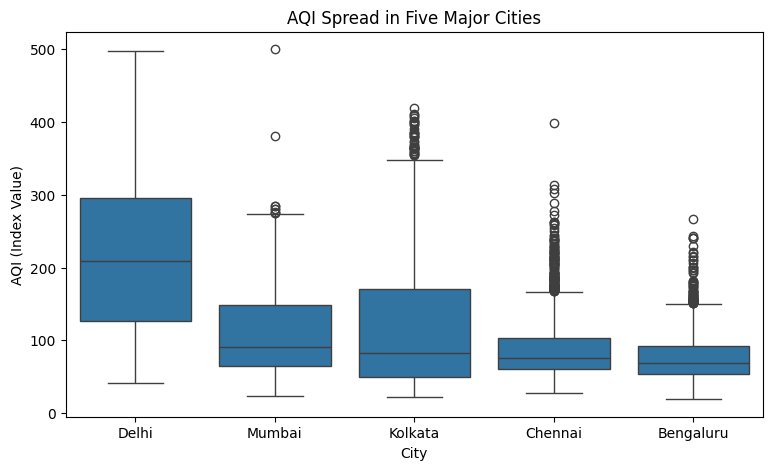

In [37]:
# 6. Box plot comparing five cities
five = ["Delhi", "Mumbai", "Kolkata", "Chennai", "Bengaluru"]
plt.figure(figsize=(9, 5))
sns.boxplot(data=df[df["City"].isin(five)], x="City", y="Index Value", order=five)
plt.title("AQI Spread in Five Major Cities")
plt.xlabel("City")
plt.ylabel("AQI (Index Value)")
plt.show()

Which city has the widest spread?

**Delhi**. It has the highest standard deviation (104) and the widest IQR (169), and Its box sits much higher,hence Delhi is both the most polluted and the most variable of the five.

Is the mean or the median better for a typical Delhi day?

 **The median (209) is the safer choice**, though here the two are close (217 vs 209).The median is better measure for delhi because it is not pulled by extreme days and would stay stable if a few critical days were added.

# 4. Which cities have the worst air?

In [38]:
# 1. Count days per city, keep cities with 2,000+ days
counts = df["City"].value_counts()
big = counts[counts >= 2000].index
df_big = df[df["City"].isin(big)]
print("Cities kept:", len(big), "| shape:", df_big.shape)

Cities kept: 54 | shape: (132735, 7)


In [39]:
# 2. Average AQI per city: 10 worst and 5 best
avg_aqi = (df_big.groupby("City")["Index Value"]
                 .mean()
                 .sort_values(ascending=False))
print("10 worst:\n", avg_aqi.head(10).round(1))
print("5 best:\n", avg_aqi.tail(5).round(1))

10 worst:
 City
Ghaziabad        221.6
Delhi            217.1
Bhiwadi          215.9
Greater Noida    211.0
Noida            206.0
Faridabad        205.6
Gurugram         198.6
Muzaffarpur      193.5
Patna            190.4
Lucknow          181.2
Name: Index Value, dtype: float64
5 best:
 City
Rajamahendravaram     84.4
Amaravati             77.5
Bengaluru             75.4
Tirupati              70.8
Thiruvananthapuram    59.2
Name: Index Value, dtype: float64


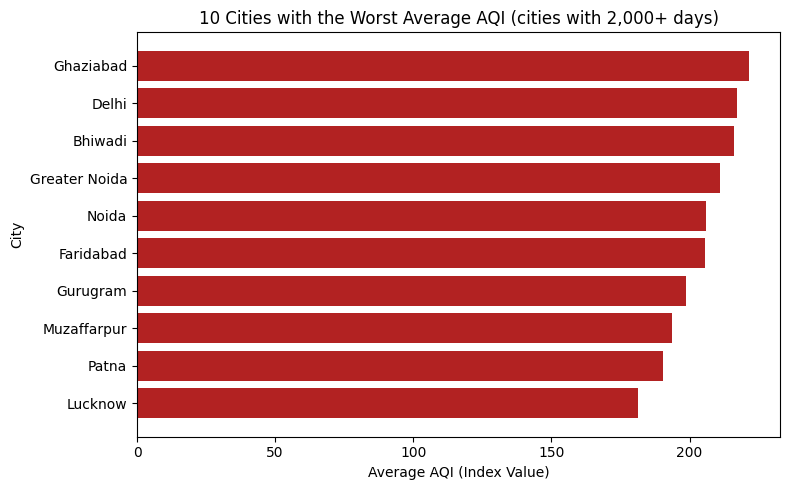

In [40]:
# 4.3 Horizontal bar chart of the 10 worst cities
worst10 = avg_aqi.head(10)
plt.figure(figsize=(8, 5))
plt.barh(worst10.index[::-1], worst10.values[::-1], color="firebrick")
plt.title("10 Cities with the Worst Average AQI (cities with 2,000+ days)")
plt.xlabel("Average AQI (Index Value)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

In [41]:
# 4.4 Share of days with AQI above 200
df_big = df_big.assign(poor_day=df_big["Index Value"] > 200)
poor_share = (df_big.groupby("City")["poor_day"]
                    .mean()
                    .mul(100)
                    .sort_values(ascending=False))
print("Top 10 by % poor days:\n", poor_share.head(10).round(1))

Top 10 by % poor days:
 City
Bhiwadi          54.4
Ghaziabad        52.6
Delhi            52.4
Greater Noida    49.1
Faridabad        46.6
Gurugram         46.3
Noida            46.2
Muzaffarpur      45.1
Patna            43.0
Lucknow          38.5
Name: poor_day, dtype: float64


In [42]:
# Compare the two lists
print("Same cities in both lists?",
      set(avg_aqi.head(10).index) == set(poor_share.head(10).index))

Same cities in both lists? True


Are the two top-10 lists the same?

They contain exactly the same 10 cities, but the order differs slightly. Ghaziabad is first by average AQI, while Bhiwadi is first by share of bad days.

What do the worst cities have in common?

Most are in the Indo-Gangetic Plain of north India. Eight of the ten are in or around the Delhi NCR region. Over half of the days in Bhiwadi, Ghaziabad and Delhi are rated Poor or worse.

# 5. When is the air worst?

In [47]:
import plotly.express as px
delhi = df[df["City"] == "Delhi"]

month
1     316.1
2     254.7
3     196.1
4     209.6
5     204.9
6     172.4
7     108.6
8     103.4
9     123.9
10    242.9
11    348.6
12    334.9
Name: Index Value, dtype: float64


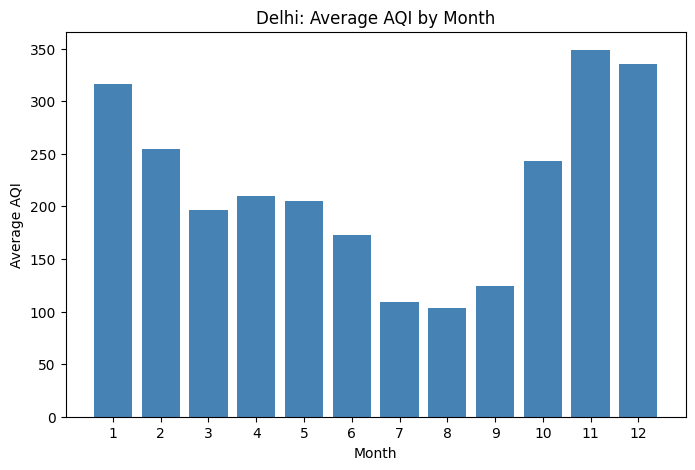

In [48]:
# 1. Average AQI by month + bar chart
monthly = delhi.groupby("month")["Index Value"].mean()
print(monthly.round(1))

plt.figure(figsize=(8, 5))
plt.bar(monthly.index, monthly.values, color="steelblue")
plt.xticks(range(1, 13))
plt.title("Delhi: Average AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.show()

year
2015    229.5
2016    256.4
2017    227.5
2018    225.4
2019    214.6
2020    185.1
2021    208.6
2022    209.2
2023    203.6
Name: Index Value, dtype: float64


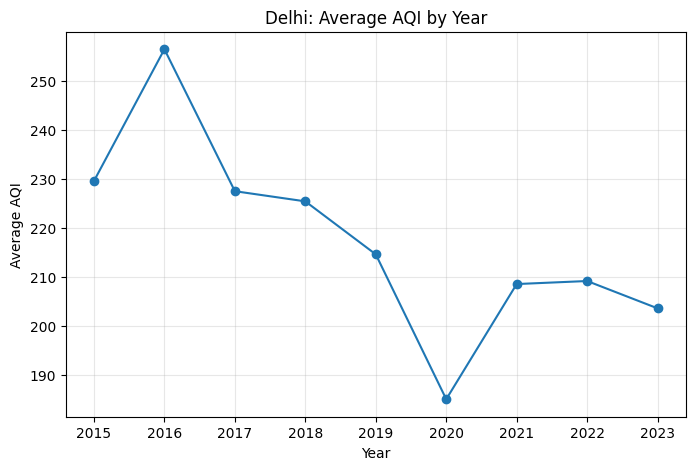

In [49]:
# 2. Average AQI by year + line chart
yearly = delhi.groupby("year")["Index Value"].mean()
print(yearly.round(1))

plt.figure(figsize=(8, 5))
plt.plot(yearly.index, yearly.values, marker="o")
plt.title("Delhi: Average AQI by Year")
plt.xlabel("Year")
plt.ylabel("Average AQI")
plt.grid(alpha=0.3)
plt.show()

In [50]:
# 3. Interactive yearly chart with Plotly (hover over each point)
yearly_df = yearly.reset_index()
fig = px.line(yearly_df, x="year", y="Index Value", markers=True,
              title="Delhi: Average AQI by Year",
              labels={"year": "Year", "Index Value": "Average AQI"})
fig.update_xaxes(dtick=1)
fig.show()

Which three months are the worst?

November (349), December (335) and January (316) because these are  winter smog season.

Has Delhi’s yearly average improved since 2019?

Yes, but mildly since Before 2019 average AQI was  about 236. After 2019 it is about 207.

# 6. Two policy questions: before and after

### A. Did the lockdown clean the air?

In [52]:
cities = ["Delhi", "Mumbai", "Kolkata", "Chennai", "Bengaluru", "Lucknow"]

In [53]:
# 1. Average AQI in April 2019 and April 2020 for each city
april = df[df["City"].isin(cities) & (df["month"] == 4) & df["year"].isin([2019, 2020])]
table = april.pivot_table(index="City", columns="year",
                          values="Index Value", aggfunc="mean").loc[cities]

In [54]:
# 2. Percentage change = (new - old) / old * 100
table["pct_change"] = (table[2020] - table[2019]) / table[2019] * 100
print(table.round(1))

year        2019   2020  pct_change
City                               
Delhi      210.7  109.8       -47.9
Mumbai      93.2   69.9       -25.0
Kolkata     80.7   66.0       -18.2
Chennai     70.5   47.3       -32.9
Bengaluru  115.3   56.2       -51.2
Lucknow    204.2  104.2       -49.0


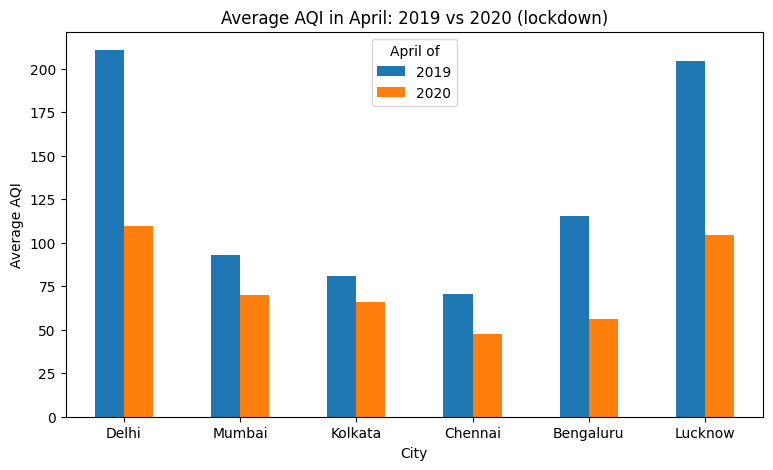

In [55]:
# 3. Grouped bar chart
table[[2019, 2020]].plot(kind="bar", figsize=(9, 5))
plt.title("Average AQI in April: 2019 vs 2020 (lockdown)")
plt.xlabel("City")
plt.ylabel("Average AQI")
plt.xticks(rotation=0)
plt.legend(title="April of")
plt.show()

### B. Does Diwali make Delhi's air worse?

In [58]:
diwali = {2015: "2015-11-11", 2016: "2016-10-30", 2017: "2017-10-19",
          2018: "2018-11-07", 2019: "2019-10-27", 2020: "2020-11-14",
          2021: "2021-11-04", 2022: "2022-10-24", 2023: "2023-11-12"}

delhi = df[df["City"] == "Delhi"]
week = pd.Timedelta(days=7)
rows = []

In [59]:
# 1. Before and after averages for each year
for year, d in diwali.items():
    d = pd.Timestamp(d)
    before = delhi[(delhi["date"] >= d - week) & (delhi["date"] < d)]["Index Value"].mean()
    after  = delhi[(delhi["date"] > d) & (delhi["date"] <= d + week)]["Index Value"].mean()
    rows.append({"year": year, "before": before, "after": after})

diwali_df = pd.DataFrame(rows)
diwali_df["difference"] = diwali_df["after"] - diwali_df["before"]
print(diwali_df.round(1))

   year  before  after  difference
0  2015   359.4  343.3       -16.1
1  2016   325.9  436.0       110.1
2  2017   290.0  343.0        53.0
3  2018   342.3  391.3        49.0
4  2019   259.7  424.9       165.1
5  2020   399.0  266.9      -132.1
6  2021   286.6  414.9       128.3
7  2022   246.3  346.4       100.1
8  2023   376.0  371.0        -5.0


In [60]:
# 2. In how many of the 9 years was "after" worse?
print("Years where after > before:", (diwali_df["difference"] > 0).sum(), "of 9")

Years where after > before: 6 of 9


In [61]:
# Optional: paired t-test
from scipy.stats import ttest_rel
print(ttest_rel(diwali_df["after"], diwali_df["before"]))

TtestResult(statistic=np.float64(1.6590610986290946), pvalue=np.float64(0.13568716626009958), df=np.int64(8))


### **Hypothesis**

**Null hypothesis**: The AQI in Delhi is same 7 days before-after diwali.
**Alternative hypothesis**: The AQI in Delhi in the 7 days after Diwali is higher than in the 7 days before it.

Which way I lean

I lean towards the alternative hypothesis, but only weakly. In 6 of the 9 years the “after” week was worse, and on average the AQI rose by about 50 points and with only 9 pairs the paired t-test gives p ≈ 0.14 so less p-value means null hypothesis is not significant.

Another reason the air gets worse in late October and November?




1.   Stubble burning in Punjab and Haryana adds smoke to the air in the same weeks.
2.   Falling temperatures and weak winds also trap pollution close to the ground.

So part of the rise after Diwali may come from the season itself rather than from crackers.

# Story

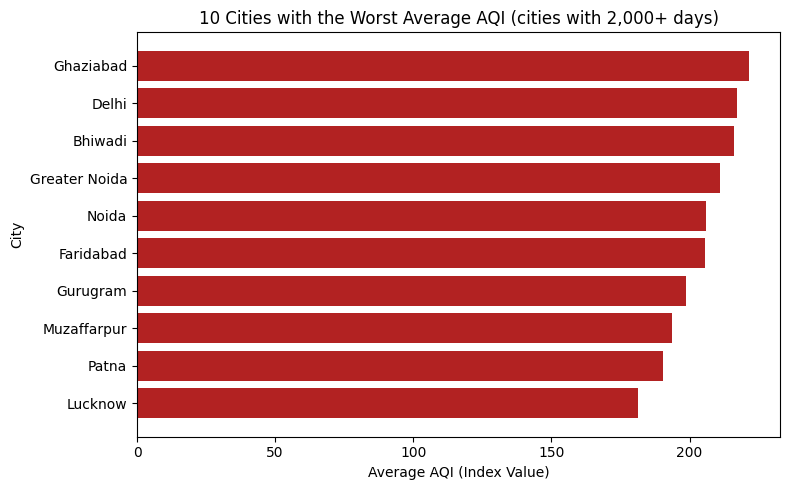

In [63]:
# Chart 1: Horizontal bar chart of the 10 worst cities.
worst10 = avg_aqi.head(10)
plt.figure(figsize=(8, 5))
plt.barh(worst10.index[::-1], worst10.values[::-1], color="firebrick")
plt.title("10 Cities with the Worst Average AQI (cities with 2,000+ days)")
plt.xlabel("Average AQI (Index Value)")
plt.ylabel("City")
plt.tight_layout()
plt.show()


The ten cities with the worst average AQI are all in north India, mostly in and around Delhi NCR, with Ghaziabad (222), Delhi (217) and Bhiwadi (216) at the top

month
1     316.1
2     254.7
3     196.1
4     209.6
5     204.9
6     172.4
7     108.6
8     103.4
9     123.9
10    242.9
11    348.6
12    334.9
Name: Index Value, dtype: float64


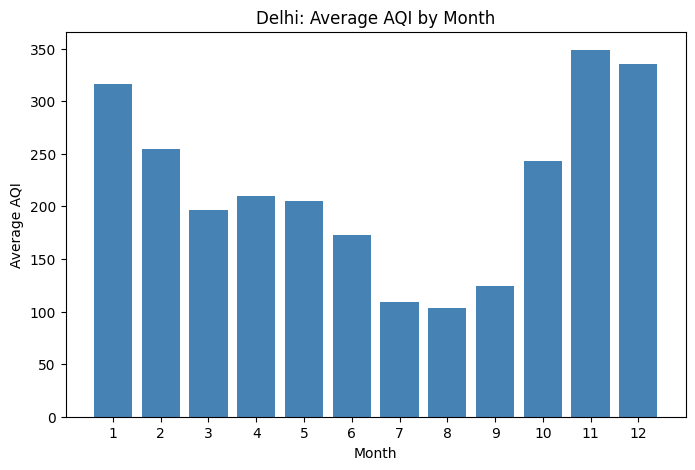

In [64]:
#Chart 2: Bar chart of Delhi’s average AQI by month
monthly = delhi.groupby("month")["Index Value"].mean()
print(monthly.round(1))

plt.figure(figsize=(8, 5))
plt.bar(monthly.index, monthly.values, color="steelblue")
plt.xticks(range(1, 13))
plt.title("Delhi: Average AQI by Month")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.show()

Delhi’s air is worst in winter, with November (349), December (335) and January (316) averaging about three times the monsoon lows of July and August (about 105)

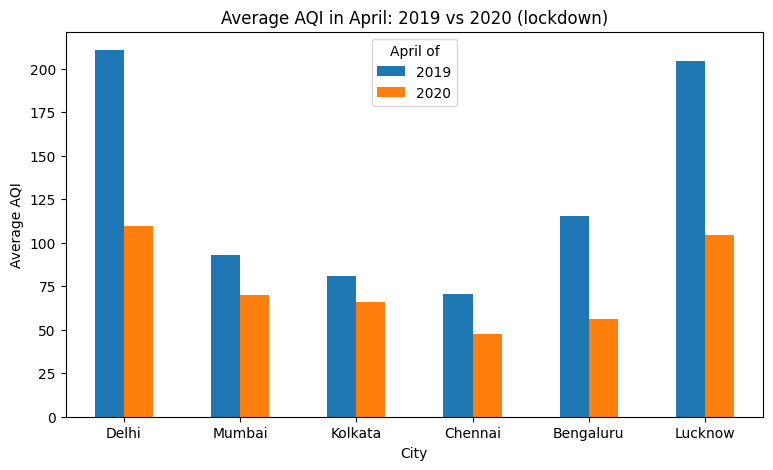

In [65]:
#Chart 3: Grouped bar chart of April 2019 vs April 2020
table[[2019, 2020]].plot(kind="bar", figsize=(9, 5))
plt.title("Average AQI in April: 2019 vs 2020 (lockdown)")
plt.xlabel("City")
plt.ylabel("Average AQI")
plt.xticks(rotation=0)
plt.legend(title="April of")
plt.show()

During the April 2020 lockdown, average AQI fell in all six cities, by 18% in Kolkata and by 48% in Delhi, showing how much traffic and industry contribute to pollution.